# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from lifelines import LogNormalAFTFitter

df = pd.read_csv('./data/ames_prices.csv')

# Question 1

In [2]:
df = pd.read_csv('./data/metabric.csv')
df.head()

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


In [3]:
tab = df['Overall Survival Status'].value_counts()
tab

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

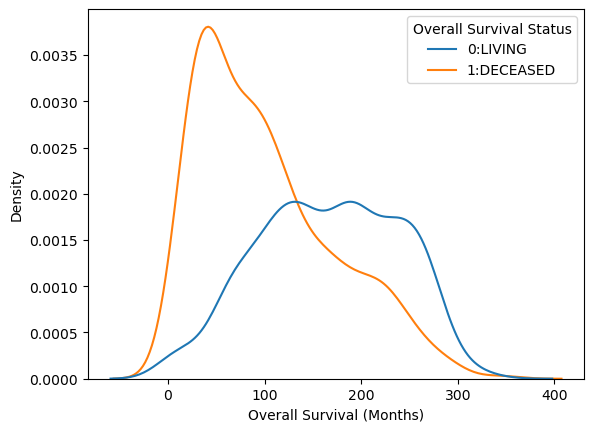

In [4]:
sns.kdeplot( x=df['Overall Survival (Months)'], hue=df['Overall Survival Status'])
plt.show()

In [5]:
df = df.query("`Tumor Stage` != 0")
df_2 = df.copy()

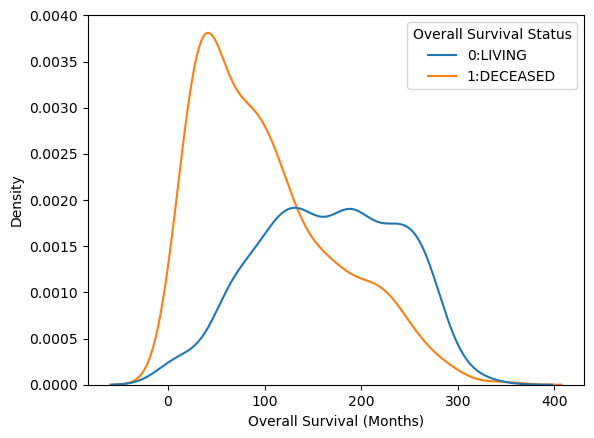

In [6]:
sns.kdeplot( x=df['Overall Survival (Months)'], hue=df['Overall Survival Status'])
plt.show()

# Question 2

In [7]:
df.columns

Index(['Age at Diagnosis', 'Type of Breast Surgery', 'Cancer Type',
       'Chemotherapy', 'Hormone Therapy', 'Lymph nodes examined positive',
       'Mutation Count', 'Nottingham prognostic index',
       'Overall Survival (Months)', 'Overall Survival Status', 'Radio Therapy',
       'TMB (nonsynonymous)', 'Tumor Size', 'Tumor Stage'],
      dtype='object')

In [8]:
df_cleaned = df_2[['Age at Diagnosis',
            'Lymph nodes examined positive',
            'Mutation Count',
            'Tumor Size',
            'Chemotherapy',
            'Hormone Therapy',
            'Radio Therapy',
            'Overall Survival (Months)',
            'Overall Survival Status',
            'Tumor Stage']]

In [9]:
df_cleaned_imputation = df_cleaned.copy()

In [10]:
y = np.log(df_cleaned_imputation['Overall Survival (Months)'])

In [11]:
df_cleaned_imputation = pd.get_dummies(df_cleaned_imputation,columns=['Chemotherapy','Hormone Therapy','Radio Therapy'],drop_first=True,dtype=float)
status_map = {'1:DECEASED':1,'0:LIVING':0}
df_cleaned_imputation['Overall Survival Status'] = df_cleaned_imputation['Overall Survival Status'].map(status_map)

In [12]:
df_cleaned_imputation.columns

Index(['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Tumor Size', 'Overall Survival (Months)', 'Overall Survival Status',
       'Tumor Stage', 'Chemotherapy_YES', 'Hormone Therapy_YES',
       'Radio Therapy_YES'],
      dtype='object')

In [13]:
X = df_cleaned_imputation[['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Tumor Size', 'Overall Survival Status',
       'Tumor Stage', 'Chemotherapy_YES', 'Hormone Therapy_YES',
       'Radio Therapy_YES']]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [14]:
wrong_imputation = LinearRegression()
wrong_imputation.fit(X,y)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
wrong_imputation_coeff = pd.Series(wrong_imputation.coef_, index=X.columns)
wrong_imputation_coeff

Age at Diagnosis                -0.003832
Lymph nodes examined positive   -0.024863
Mutation Count                   0.015210
Tumor Size                      -0.001211
Overall Survival Status         -0.542240
Tumor Stage                     -0.173536
Chemotherapy_YES                -0.222550
Hormone Therapy_YES              0.040464
Radio Therapy_YES                0.028029
dtype: float64

In [16]:
prediction_imputation = wrong_imputation.predict(X_test)
prediction_imputation

array([5.22821511, 4.38429871, 5.24348254, 4.4590125 , 5.11344844,
       4.92282138, 5.10345897, 5.10524903, 4.33556851, 4.54395918,
       4.5167858 , 4.6649083 , 5.08204629, 3.96075413, 4.41751197,
       5.08077572, 4.54298152, 4.90339492, 3.944587  , 4.14820886,
       4.94102633, 4.03496284, 3.52302063, 4.66629511, 5.14571024,
       5.10485915, 3.65869353, 3.87826895, 5.12930857, 4.94742684,
       4.1543136 , 4.28940639, 4.59593581, 5.03494774, 4.37306674,
       4.67536492, 4.97144512, 4.30346929, 4.58955673, 4.3412355 ,
       4.16980667, 4.52687353, 4.35459562, 4.63181685, 4.41763503,
       5.0424122 , 4.96413149, 4.50619925, 4.3091813 , 4.17951993,
       4.11554676, 4.78313314, 5.06482293, 4.38173939, 4.36419578,
       4.94422948, 4.36575013, 4.92818344, 4.34006399, 4.34250683,
       4.90481721, 5.21069187, 4.58001609, 5.11039501, 4.59071542,
       5.22770275, 4.03185628, 4.92205136, 4.1267566 , 5.0760045 ,
       5.04253985, 4.35389343, 4.20823977, 5.14976985, 4.28591

In [17]:
df_cleaned_drop = df_cleaned_imputation.copy()
df_cleaned_drop = df_cleaned_drop.query('`Overall Survival Status` != 0')

In [18]:
df_cleaned_drop.columns

Index(['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Tumor Size', 'Overall Survival (Months)', 'Overall Survival Status',
       'Tumor Stage', 'Chemotherapy_YES', 'Hormone Therapy_YES',
       'Radio Therapy_YES'],
      dtype='object')

In [19]:
X = df_cleaned_drop[['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Tumor Size', 'Tumor Stage', 'Chemotherapy_YES', 'Hormone Therapy_YES',
       'Radio Therapy_YES']]
y = np.log(df_cleaned_drop['Overall Survival (Months)'])

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)
wrong_drop_alive = LinearRegression()
wrong_drop_alive.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
wrong_drop_alive_coeff = pd.Series(wrong_drop_alive.coef_, index=X.columns)
wrong_drop_alive_coeff

Age at Diagnosis                -0.003072
Lymph nodes examined positive   -0.026828
Mutation Count                   0.008780
Tumor Size                      -0.000846
Tumor Stage                     -0.267393
Chemotherapy_YES                -0.365142
Hormone Therapy_YES              0.224655
Radio Therapy_YES                0.005909
dtype: float64

In [22]:
prediction_drop_alive = wrong_drop_alive.predict(X_test)
prediction_drop_alive

array([3.96147488, 4.27503909, 4.4800703 , 4.4591174 , 4.69126783,
       4.24406909, 4.78932334, 4.39223547, 4.07860819, 4.78970942,
       4.22949151, 4.20759712, 4.57016359, 4.39201322, 4.18002606,
       4.85728778, 4.52551635, 4.47371132, 4.08747933, 4.50262276,
       4.43410238, 4.58827965, 3.79682146, 4.75006123, 3.2579514 ,
       3.7423382 , 4.46353492, 4.40990841, 4.1611433 , 3.99115623,
       4.06789807, 3.76649812, 3.99578125, 4.50475078, 4.42593148,
       4.50083793, 4.75303771, 4.44198113, 4.43489121, 4.33739832,
       4.7639875 , 3.82153169, 3.87776879, 4.42827546, 4.06438501,
       3.89611767, 4.54357751, 4.83726277, 4.32920184, 4.19522054,
       4.46005744, 4.47129234, 4.56060057, 4.05159709, 4.6882317 ,
       4.4625789 , 4.56826282, 4.57673843, 4.4209761 , 4.06845479,
       4.29138249, 4.43657759, 4.06012801, 4.50799994, 4.8289401 ,
       3.42683063, 4.2491377 , 4.41144174, 3.92203887, 4.09612373,
       4.14108826, 4.52775415, 4.20500782, 4.13333756, 4.41849

The method is imputation because you are assuming that the people who lived, only lived up to the end of the study which is underestimating the true number of survival months for those individuals leading to inaccurate models. The second treats survival as missing data as it simply drops the people who were alive at the time the study ended meaning the regression and coefficients are only prediciting survival months for people who died as it is only trained on data in which the patient died.  

# Explain write for Question 3

# Question 4

In [23]:
y = df_cleaned['Overall Survival (Months)']

In [24]:
df_cleaned = pd.get_dummies(df_cleaned,columns=['Chemotherapy','Hormone Therapy','Radio Therapy'],drop_first=True,dtype=float)
status_map = {'1:DECEASED':1,'0:LIVING':0}
df_cleaned['Overall Survival Status'] = df_cleaned['Overall Survival Status'].map(status_map)

In [25]:
X = df_cleaned[['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count',
       'Tumor Size', 'Overall Survival Status',
       'Tumor Stage', 'Chemotherapy_YES', 'Hormone Therapy_YES',
       'Radio Therapy_YES']]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [26]:
df_combined = pd.concat([y_train,X_train],axis=1)

In [27]:
model_combined = LogNormalAFTFitter()
model_combined.fit(df_combined,duration_col='Overall Survival (Months)',event_col='Overall Survival Status')

<lifelines.LogNormalAFTFitter: fitted with 1072 total observations, 452 right-censored observations>

In [28]:
model_combined.params_["mu_"]

covariate
Age at Diagnosis                -0.021272
Chemotherapy_YES                -0.260579
Hormone Therapy_YES              0.216191
Lymph nodes examined positive   -0.049032
Mutation Count                  -0.012317
Radio Therapy_YES                0.177378
Tumor Size                      -0.005758
Tumor Stage                     -0.313003
Intercept                        6.945923
dtype: float64

In [29]:
model_combined.predict_median(X_test)

943     81.608548
187    230.473396
439    151.842898
57     120.509392
91     206.916010
          ...    
48     183.395448
572    179.951932
789    154.983079
206    166.618525
214    293.096332
Length: 269, dtype: float64

In [30]:
''' 


class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))] 

#model = CensoredNormalMLE(y_train, X_train, train["event"])  
model = CensoredNormalMLE(y_train, X_train, df['Overall Survival Status'])  
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

'''


' \n\n\nclass CensoredNormalMLE(GenericLikelihoodModel):\n    def __init__(self, endog, exog, event):\n        super().__init__(endog, exog, extra_params_names=["log_sigma"])\n        self.event = np.asarray(event)\n\n    def nloglikeobs(self, params):\n        beta, log_sigma = params[:-1], params[-1]\n        sigma = np.exp(log_sigma)\n        z = (self.endog - self.exog @ beta) / sigma\n        ll_dead = norm.logpdf(z) - log_sigma\n        ll_alive = norm.logsf(z)\n        return -np.where(self.event == 1, ll_dead, ll_alive)\n\nstart = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))] \n\n#model = CensoredNormalMLE(y_train, X_train, train["event"])  \nmodel = CensoredNormalMLE(y_train, X_train, df[\'Overall Survival Status\'])  \nmle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)\n\nprint("Converged:", mle.mle_retvals["converged"])\nprint(mle.summary())\n\n'

# Question 5

Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 